In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [14]:
df = pd.read_csv("SkyCity Auckland Restaurants & Bars.csv")
df

,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,UberEatsOrders,DoorDashOrders,SelfDeliveryOrders,UberEatsRevenue,DoorDashRevenue,SelfDeliveryRevenue,COGSRate,OPEXRate,CommissionRate,DeliveryRadiusKM,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,8662.09,212,118,141,9321.64,5188.46,6199.77,0.208741,0.366172,0.28,11,3.25,458.25,3682.14,1352.45,752.78,2177.19,0.42,0.45,0.25,0.3
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,10476.55,508,282,339,20548.60,11406.90,13712.55,0.248217,0.407613,0.28,16,4.72,1600.08,3605.72,1318.61,731.99,3119.38,0.23,0.45,0.25,0.3
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,20975.72,537,298,358,21496.11,11928.94,14330.74,0.219688,0.407932,0.30,11,3.25,1163.50,7810.95,1555.90,863.42,4172.99,0.44,0.45,0.25,0.3
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,7836.48,390,217,260,14149.20,7872.76,9432.80,0.237291,0.437815,0.33,3,0.89,231.40,2546.02,-72.25,-40.20,2833.26,0.25,0.45,0.25,0.3
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,8962.74,436,242,291,14972.24,8310.28,9992.94,0.221438,0.433457,0.33,9,2.66,774.06,3093.09,226.17,125.53,2674.56,0.27,0.45,0.25,0.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1691,Thai,26412,Lotus Bistro,Ghost Kitchen,North Shore,1.03,45.81,487,31,1420.11,228,137,91,10444.68,6275.97,4168.71,0.256343,0.218022,0.30,17,5.02,456.82,746.46,2356.69,1416.08,1734.40,0.07,0.50,0.30,0.2
1692,Thai,26275,Dragon Bistro,Ghost Kitchen,North Shore,1.03,44.20,956,62,2740.40,447,268,179,19757.40,11845.60,7911.80,0.288360,0.223346,0.30,17,5.02,898.58,1338.12,3720.20,2230.45,2964.70,0.07,0.50,0.30,0.2
1693,Thai,26454,Dragon Corner,QSR,South Auckland,1.05,44.72,758,62,2772.64,348,209,139,15562.56,9346.48,6216.08,0.240116,0.410384,0.32,5,1.48,205.72,969.04,459.09,275.72,1966.80,0.09,0.50,0.30,0.2
1694,Thai,25699,Golden Corner,Cafe,North Shore,1.03,36.98,1084,124,4585.52,480,288,192,17750.40,10650.24,7100.16,0.274149,0.380041,0.28,5,1.48,284.16,1585.72,1168.16,700.90,2171.15,0.13,0.50,0.30,0.2


In [15]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1696 entries, 0 to 1695
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CuisineType            1696 non-null   str    
 1   RestaurantID           1696 non-null   int64  
 2   RestaurantName         1696 non-null   str    
 3   Segment                1696 non-null   str    
 4   Subregion              1696 non-null   str    
 5   GrowthFactor           1696 non-null   float64
 6   AOV                    1696 non-null   float64
 7   MonthlyOrders          1696 non-null   int64  
 8   InStoreOrders          1696 non-null   int64  
 9   InStoreRevenue         1696 non-null   float64
 10  UberEatsOrders         1696 non-null   int64  
 11  DoorDashOrders         1696 non-null   int64  
 12  SelfDeliveryOrders     1696 non-null   float64
 13  UberEatsRevenue        1696 non-null   float64
 14  DoorDashRevenue        1696 non-null   float64
 15  SelfDeliveryRev

In [16]:
raw_df.isnull().sum()

CuisineType              0
RestaurantID             0
RestaurantName           0
Segment                  0
Subregion                0
GrowthFactor             0
AOV                      0
MonthlyOrders            0
InStoreOrders            0
InStoreRevenue           0
UberEatsOrders           0
DoorDashOrders           0
SelfDeliveryOrders       0
UberEatsRevenue          0
DoorDashRevenue          0
SelfDeliveryRevenue      0
COGSRate                 0
OPEXRate                 0
CommissionRate           0
DeliveryRadiusKM         0
DeliveryCostPerOrder     0
SD_DeliveryTotalCost     0
InStoreNetProfit         0
UberEatsNetProfit        0
DoorDashNetProfit        0
SelfDeliveryNetProfit    0
InStoreShare             0
UE_share                 0
DD_share                 0
SD_share                 0
dtype: int64

In [17]:
num_cols = raw_df.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    Q1 = raw_df[col].quantile(0.25)
    Q3 = raw_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = raw_df[(raw_df[col] < lower_limit) | (raw_df[col] > upper_limit)]
    print(f"\n{col}: {len(outliers)} outliers")

    # plt.figure(figsize=(8, 2))
    # plt.boxplot(raw_df[col], vert=False)
    # plt.title(f'Boxplot of {col}')
    # plt.xlabel(col)
    # plt.show()


RestaurantID: 0 outliers

GrowthFactor: 0 outliers

AOV: 0 outliers

MonthlyOrders: 0 outliers

InStoreOrders: 0 outliers

InStoreRevenue: 0 outliers

UberEatsOrders: 0 outliers

DoorDashOrders: 0 outliers

SelfDeliveryOrders: 0 outliers

UberEatsRevenue: 0 outliers

DoorDashRevenue: 0 outliers

SelfDeliveryRevenue: 0 outliers

COGSRate: 0 outliers

OPEXRate: 0 outliers

CommissionRate: 0 outliers

DeliveryRadiusKM: 0 outliers

DeliveryCostPerOrder: 0 outliers

SD_DeliveryTotalCost: 0 outliers

InStoreNetProfit: 0 outliers

UberEatsNetProfit: 0 outliers

DoorDashNetProfit: 0 outliers

SelfDeliveryNetProfit: 0 outliers

InStoreShare: 0 outliers

UE_share: 0 outliers

DD_share: 0 outliers

SD_share: 0 outliers


In [18]:
num_cols = raw_df.select_dtypes(include=['int64', 'float64']).columns

# Capping outliers using mask()
for col in num_cols:
    Q1 = raw_df[col].quantile(0.25)
    Q3 = raw_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    raw_df[col] = raw_df[col].mask(raw_df[col] < lower_limit, lower_limit)
    raw_df[col] = raw_df[col].mask(raw_df[col] > upper_limit, upper_limit)

In [19]:
for col in num_cols:
    Q1 = raw_df[col].quantile(0.25)
    Q3 = raw_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = raw_df[(raw_df[col] < lower_limit) | (raw_df[col] > upper_limit)]
    print(f"\n{col}: {len(outliers)} outliers")


RestaurantID: 0 outliers

GrowthFactor: 0 outliers

AOV: 0 outliers

MonthlyOrders: 0 outliers

InStoreOrders: 0 outliers

InStoreRevenue: 0 outliers

UberEatsOrders: 0 outliers

DoorDashOrders: 0 outliers

SelfDeliveryOrders: 0 outliers

UberEatsRevenue: 0 outliers

DoorDashRevenue: 0 outliers

SelfDeliveryRevenue: 0 outliers

COGSRate: 0 outliers

OPEXRate: 0 outliers

CommissionRate: 0 outliers

DeliveryRadiusKM: 0 outliers

DeliveryCostPerOrder: 0 outliers

SD_DeliveryTotalCost: 0 outliers

InStoreNetProfit: 0 outliers

UberEatsNetProfit: 0 outliers

DoorDashNetProfit: 0 outliers

SelfDeliveryNetProfit: 0 outliers

InStoreShare: 0 outliers

UE_share: 0 outliers

DD_share: 0 outliers

SD_share: 0 outliers


In [20]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = raw_df.select_dtypes(include=["object"]).columns

encoder = OneHotEncoder(drop="first", sparse_output=False)
encoded = encoder.fit_transform(raw_df[cat_cols])

encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(cat_cols), index=raw_df.index)

C:\Users\pvans\AppData\Local\Temp\ipykernel_15972\869337594.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = raw_df.select_dtypes(include=["object"]).columns


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_num = scaler.fit_transform(raw_df[num_cols])

scaled_num_df = pd.DataFrame(scaled_num, columns=num_cols, index=raw_df.index)

In [24]:
from sklearn.decomposition import PCA

numeric_df = df.select_dtypes(include="number").dropna()
X_scaled = StandardScaler().fit_transform(numeric_df)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original features:", df.shape[1])
print("PCA components:", X_pca.shape[1])




Original features: 30
PCA components: 2


In [25]:
X_scaled = scaled_num_df

K = 2, Inertia = 35439.18, Silhouette = 0.187
K = 3, Inertia = 30071.25, Silhouette = 0.199
K = 4, Inertia = 26220.61, Silhouette = 0.192
K = 5, Inertia = 25062.96, Silhouette = 0.145
K = 6, Inertia = 23098.26, Silhouette = 0.167
K = 7, Inertia = 22041.07, Silhouette = 0.160
K = 8, Inertia = 21415.87, Silhouette = 0.141
K = 9, Inertia = 20222.77, Silhouette = 0.146
K = 10, Inertia = 19598.42, Silhouette = 0.143


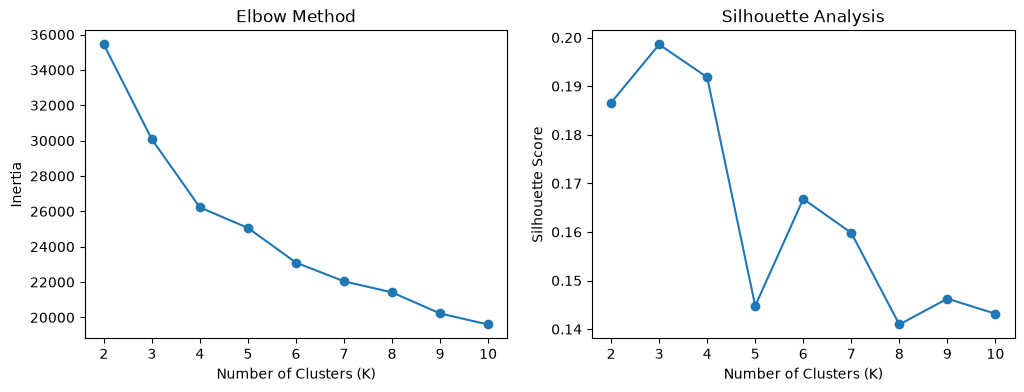

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_scores = []
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    inertia_scores.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

    print(f"K = {k}, Inertia = {kmeans.inertia_:.2f}, Silhouette = {silhouette_score(X_scaled, labels):.3f}")

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(range(2,11), inertia_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.subplot(1,2,2)
plt.plot(range(2,11), silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")

plt.show()

In [27]:
final_k = 3

kmeans_model = KMeans(n_clusters=final_k, random_state=42)
df["KMeans_Cluster"] = kmeans_model.fit_predict(X_scaled)

In [28]:
df["KMeans_Cluster"] = kmeans_model.fit_predict(X_scaled)

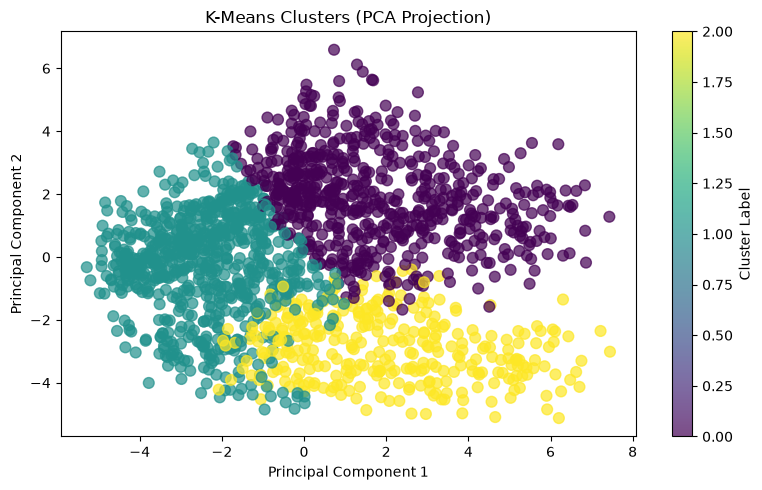

In [29]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_model = PCA(n_components=2, random_state=42)
X_pca_2d = pca_model.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    s=60,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (PCA Projection)")
plt.colorbar(label="Cluster Label")
plt.tight_layout()
plt.show()

In [30]:
df.groupby("KMeans_Cluster")[num_cols].mean()

,RestaurantID,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,UberEatsOrders,DoorDashOrders,SelfDeliveryOrders,UberEatsRevenue,DoorDashRevenue,SelfDeliveryRevenue,COGSRate,OPEXRate,CommissionRate,DeliveryRadiusKM,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
KMeans_Cluster,,,,,,,,,,,,,,,,,,,,,,,,,,
0,25846.400000,1.029952,38.988065,1483.167742,242.506452,9445.965839,588.967742,320.988710,330.704839,22939.726000,12501.768645,12890.577484,0.244080,0.379183,0.300823,10.517742,3.105226,1026.831403,3482.079226,1733.133226,947.884984,3845.647097,0.200887,0.472177,0.257419,0.270403
1,25836.480537,1.026953,38.211812,802.977181,120.558389,4583.529181,344.324832,188.327517,149.766443,13123.158577,7177.192564,5699.258416,0.267753,0.398572,0.299839,10.589262,3.126456,463.538403,1415.890228,522.164537,289.506644,1478.844054,0.186510,0.501477,0.274094,0.224430
2,25879.486405,1.028006,38.320967,1514.658610,396.438066,15145.468308,539.791541,292.501511,285.927492,20595.130604,11151.891027,10909.579245,0.375612,0.501898,0.300242,10.601208,3.129879,905.854653,1857.069547,-3640.686103,-1970.540453,429.723323,0.360151,0.480967,0.259970,0.259063


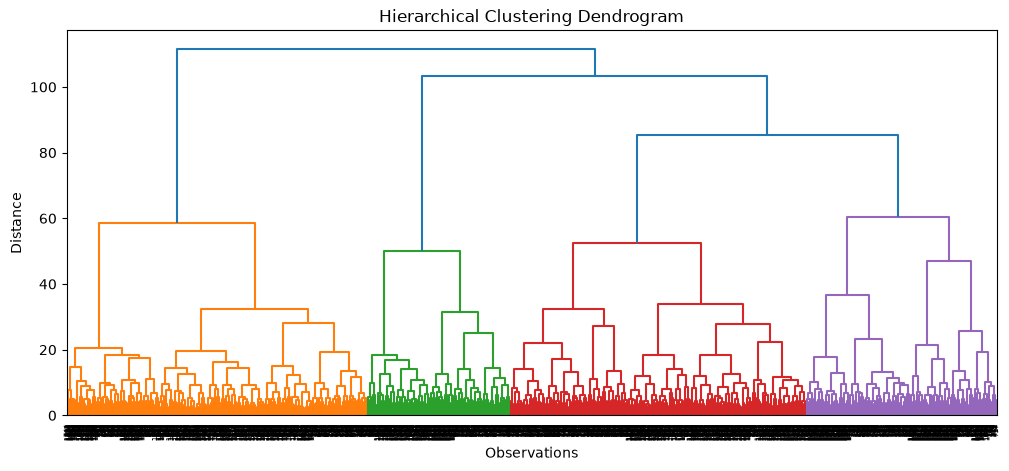

In [31]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12,5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Distance")
plt.show()

In [32]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
df["Hierarchical_Cluster"] = hc.fit_predict(X_scaled)

In [33]:
df["Hierarchical_Cluster"].value_counts()

Hierarchical_Cluster
0    887
1    549
2    260
Name: count, dtype: int64

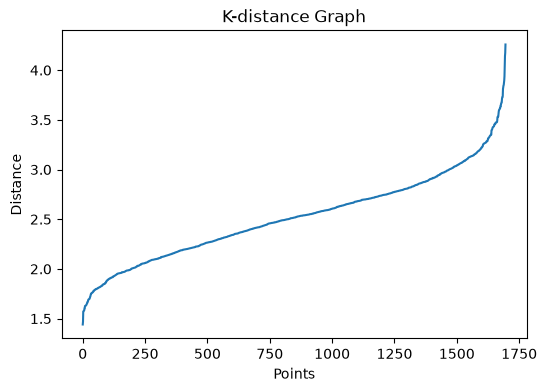

In [34]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4])

plt.figure(figsize=(6,4))
plt.plot(distances)
plt.title("K-distance Graph")
plt.xlabel("Points")
plt.ylabel("Distance")
plt.show()

In [35]:
dbscan = DBSCAN(eps=1.2, min_samples=5)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

In [36]:
df["DBSCAN_Cluster"].value_counts()

DBSCAN_Cluster
-1    1696
Name: count, dtype: int64

In [43]:
cluster_profile = (
    df.groupby("KMeans_Cluster")[[
        "GrowthFactor",
        "MonthlyOrders",
        "AOV",
        "COGSRate",
        "OPEXRate",
        "CommissionRate",
        "DeliveryRadiusKM"
    ]]
    .mean()
    .round(2)
)

cluster_profile
 

,GrowthFactor,MonthlyOrders,AOV,COGSRate,OPEXRate,CommissionRate,DeliveryRadiusKM
KMeans_Cluster,,,,,,,
0,1.03,1483.17,38.99,0.24,0.38,0.3,10.52
1,1.03,802.98,38.21,0.27,0.40,0.3,10.59
2,1.03,1514.66,38.32,0.38,0.50,0.3,10.60


In [44]:
cluster_labels = {
    0: "High-Growth, High-Risk Expanders",
    1: "Stable Core Performers",
    2: "Channel-Driven Growth Candidates"
}

df["Cluster_Label"] = df["Cluster"].map(cluster_labels)

In [45]:
gpi_features = [
    "GrowthFactor",
    "MonthlyOrders",
    "AOV",
    "COGSRate",
    "OPEXRate",
    "CommissionRate",
    "DeliveryRadiusKM"
]

In [47]:
gpi_scaler = StandardScaler()
gpi_scaled = gpi_scaler.fit_transform(df[gpi_features])

gpi_df = pd.DataFrame(
    gpi_scaled,
    columns=gpi_features,
    index=df.index
)


In [48]:
df["GPI"] = (
    0.30 * gpi_df["GrowthFactor"] +
    0.25 * gpi_df["MonthlyOrders"] +
    0.15 * gpi_df["AOV"] -
    0.10 * gpi_df["COGSRate"] -
    0.10 * gpi_df["OPEXRate"] -
    0.05 * gpi_df["CommissionRate"] +
    0.05 * gpi_df["DeliveryRadiusKM"]
)


In [49]:
df["GPI_Rank"] = df["GPI"].rank(method="dense", ascending=False)

In [50]:
cluster_gpi_summary = (
    df.groupby("Cluster_Label")[["GPI"]]
    .agg(["mean", "min", "max", "count"])
    .round(3)
)

cluster_gpi_summary

GPI                    
                                   mean    min    max count
Cluster_Label                                              
Channel-Driven Growth Candidates -0.225 -1.263  0.462   286
High-Growth, High-Risk Expanders  0.194 -0.701  0.951   177
Stable Core Performers           -0.061 -1.018  0.623   176

In [51]:
df["GPI_Rank"] = df["GPI"].rank(ascending=False)

In [52]:
df["GPI_Rank"].sort_values(ascending=True).head(5)

293     1.0
1453    2.0
1551    3.0
762     4.0
98      5.0
Name: GPI_Rank, dtype: float64

In [53]:
df["RestaurantID"] = raw_df["RestaurantID"].values

In [54]:
model_output = df[["RestaurantID","Cluster","GPI","GPI_Rank"]].copy()

In [55]:
cluster_labels = { 0: "High-Growth", 1: "Stable Performers", 2: "Dependent Low Margin"}

model_output["Cluster_Label"] = model_output["Cluster"].map(cluster_labels)

In [56]:
final_df = raw_df.merge(model_output,on="RestaurantID",how="left")
final_df.to_csv("Resturant_Analysis.csv", index=False)

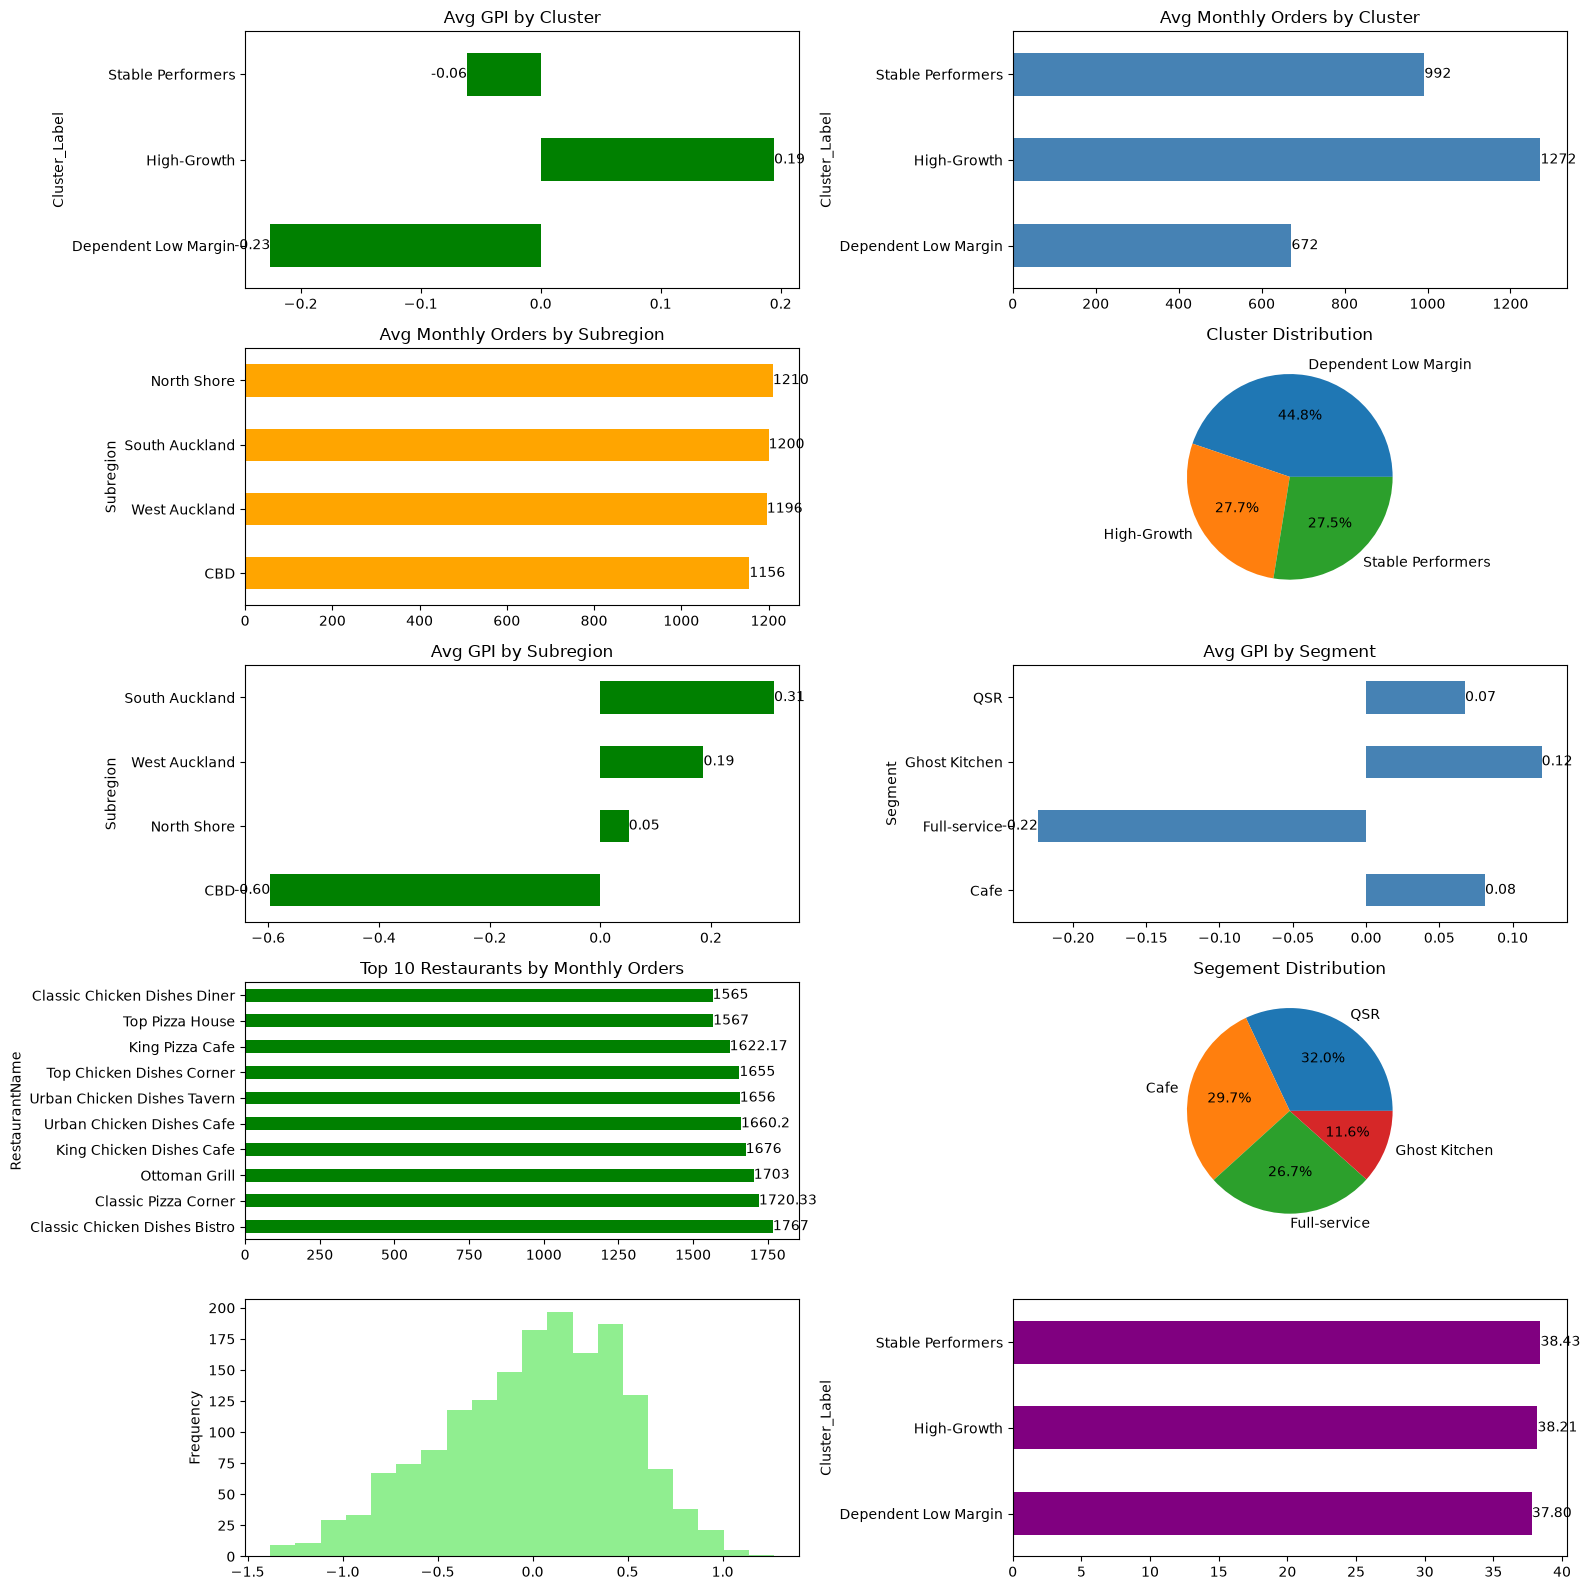

In [57]:
plt.figure(figsize=(16, 16))

# 1. Avg GPI by Cluster
plt.subplot(5, 2, 1)
p1 = final_df.groupby("Cluster_Label")["GPI"].mean().plot(kind="barh", color="green" ,title= "Avg GPI by Cluster")
p1.bar_label(p1.containers[0], fmt="%.2f")

# 2. Avg Monthly Orders by Cluster
plt.subplot(5, 2, 2)
p2 = final_df.groupby("Cluster_Label")["MonthlyOrders"].mean().plot(kind="barh", color="steelblue", title= "Avg Monthly Orders by Cluster")
p2.bar_label(p2.containers[0], fmt="%.0f")

# 3. Avg Monthly Orders by Subregion
plt.subplot(5, 2, 3)
p3 = final_df.groupby("Subregion")["MonthlyOrders"].mean().sort_values().plot(kind="barh", color="orange", title= "Avg Monthly Orders by Subregion")
p3.bar_label(p3.containers[0], fmt="%.0f")

# 4. Cluster Distribution (Pie)
plt.subplot(5, 2, 4)
final_df["Cluster_Label"].value_counts().plot(kind="pie", autopct="%1.1f%%", title= "Cluster Distribution")

# 5. Avg GPI by Subregion
plt.subplot(5, 2, 5)
p5 = final_df.groupby("Subregion")["GPI"].mean().sort_values().plot(kind="barh", color="green", title= "Avg GPI by Subregion")
p5.bar_label(p5.containers[0], fmt="%.2f")

# 6. Avg GPI by Segment
plt.subplot(5, 2, 6)
p6 = final_df.groupby("Segment")["GPI"].mean().plot(kind="barh", color="steelblue", title= "Avg GPI by Segment")
p6.bar_label(p6.containers[0], fmt="%.2f")

# 7. Top 10 Restaurants by Monthly Orders
plt.subplot(5, 2, 7)
p7 = final_df.groupby("RestaurantName")["MonthlyOrders"].mean().round(2).sort_values(ascending=False).head(10).plot(kind="barh", color="green", title= "Top 10 Restaurants by Monthly Orders")
p7.bar_label(p7.containers[0])

# 8. Segment Distribution (Pie)
plt.subplot(5, 2, 8)
final_df["Segment"].value_counts().plot(kind="pie", autopct="%1.1f%%", title= "Segement Distribution")

# 9. GPI Distribution
plt.subplot(5, 2, 9)
final_df["GPI"].plot(kind="hist", bins=20, color="lightgreen")

# 10. Avg AOV by Cluster
plt.subplot(5, 2, 10)
p10 = final_df.groupby("Cluster_Label")["AOV"].mean().plot(kind="barh", color="purple")
p10.bar_label(p10.containers[0], fmt="%.2f")

plt.tight_layout()
plt.show()

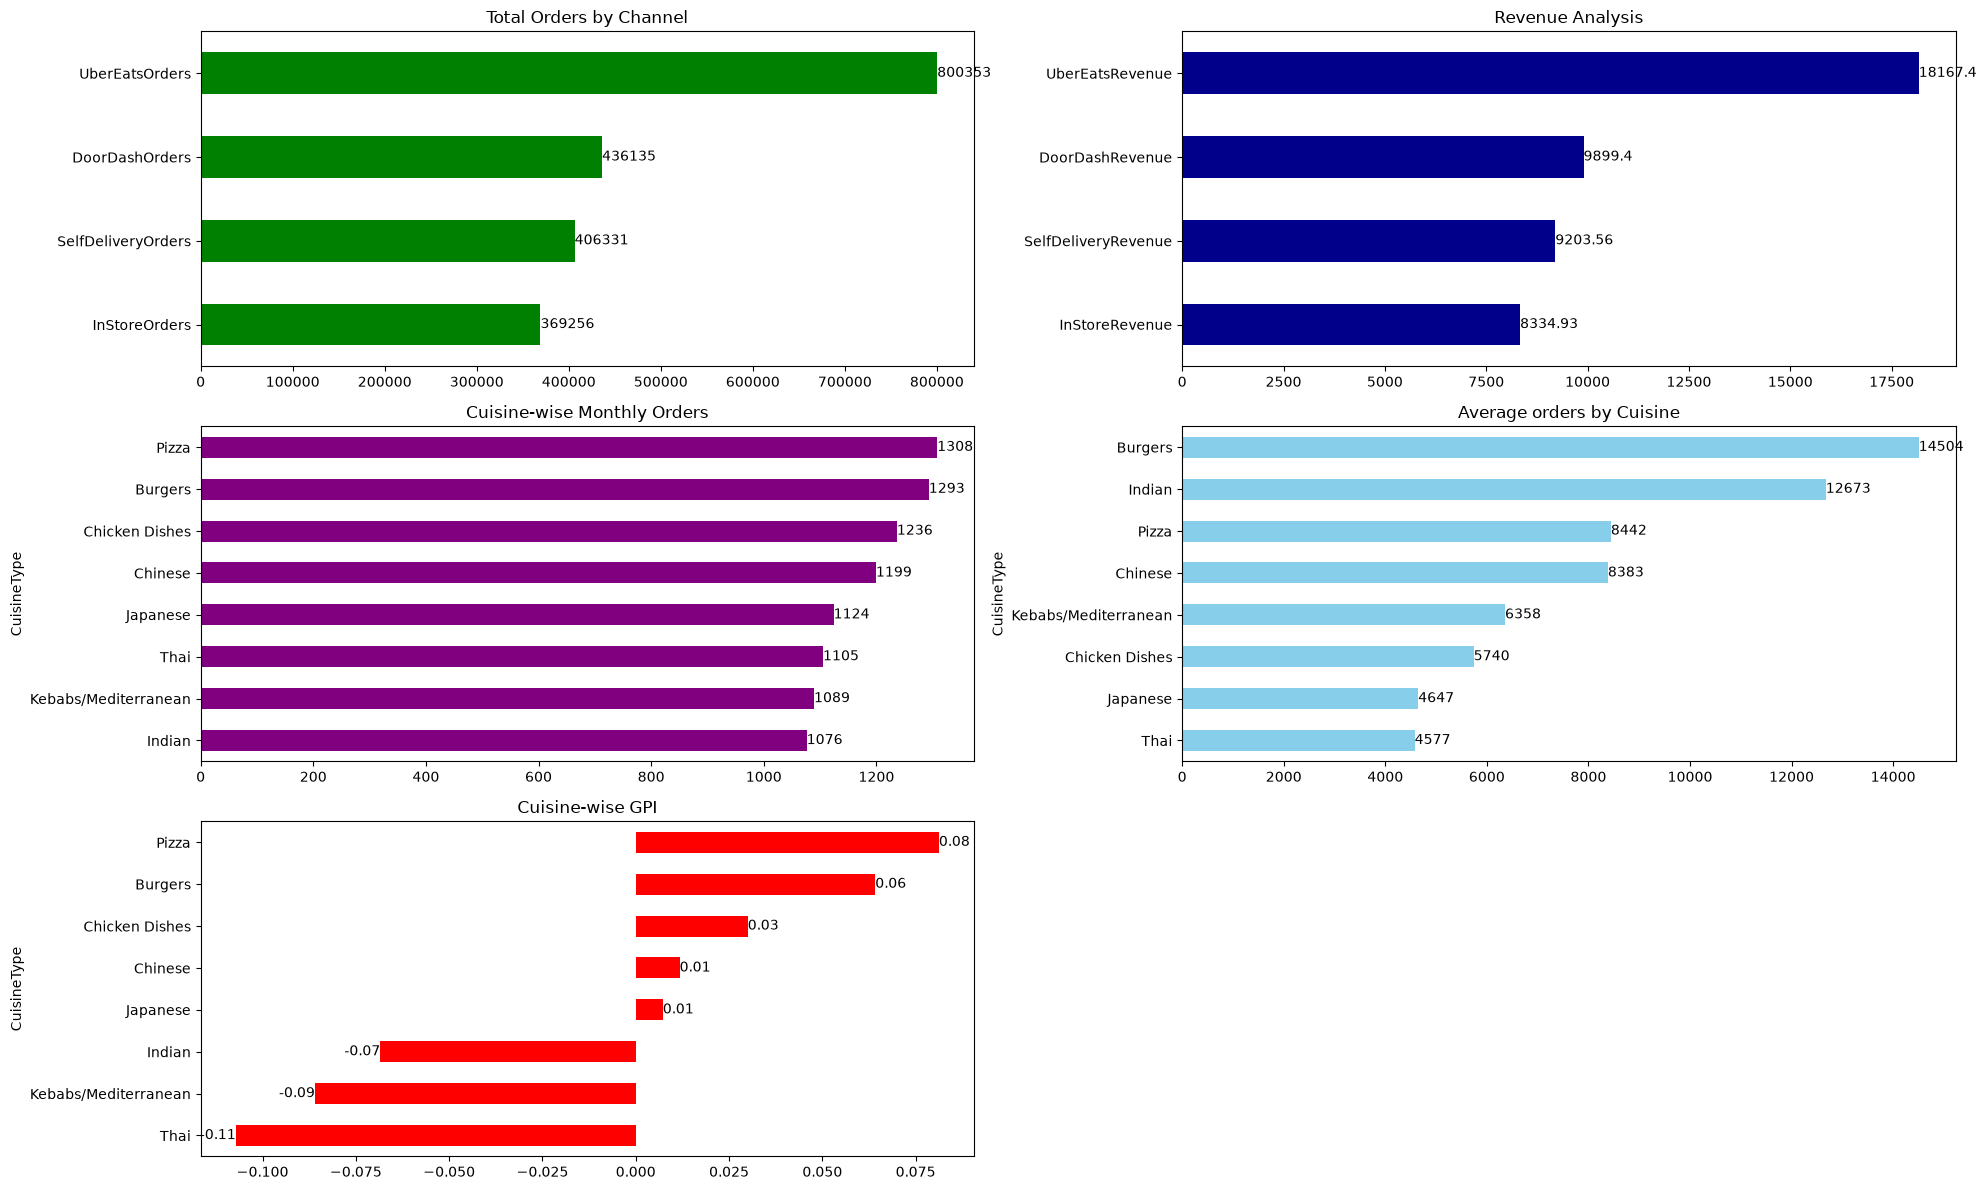

In [58]:
plt.figure(figsize=(20, 12))

# 1. Order Analysis (All Channels)
plt.subplot(3, 2, 1)
order_totals = final_df[
    ["InStoreOrders", "UberEatsOrders", "DoorDashOrders", "SelfDeliveryOrders"]
].sum()
p1 = order_totals.sort_values().plot(kind="barh", color="green", title="Total Orders by Channel")
p1.bar_label(p1.containers[0])

# 2. Revenue Analysis (All Channels)
plt.subplot(3, 2, 2)
revenue_totals = final_df[
    ["InStoreRevenue", "UberEatsRevenue", "DoorDashRevenue", "SelfDeliveryRevenue"]
].mean()
p2 = revenue_totals.sort_values().plot(kind="barh", color="darkblue", title= "Revenue Analysis")
p2.bar_label(p2.containers[0])

# 3. Cuisine-wise Monthly Orders
plt.subplot(3, 2, 3)
p3 = final_df.groupby("CuisineType")["MonthlyOrders"].mean().sort_values().plot(
    kind="barh", color="purple", title = "Cuisine-wise Monthly Orders"
)
p3.bar_label(p3.containers[0], fmt="%.0f")

# 4. Cuisine-wise Revenue
plt.subplot(3, 2, 4)
p4 = final_df.groupby("CuisineType")["AOV"].sum().sort_values().plot(
    kind="barh", color="skyblue", title=  "Average orders by Cuisine"
)
p4.bar_label(p4.containers[0], fmt="%.0f")

# 5. Cuisine-wise GPI
plt.subplot(3, 2, 5)
p5 = final_df.groupby("CuisineType")["GPI"].mean().sort_values().plot(
    kind="barh", color="red", title="Cuisine-wise GPI"
)
p5.bar_label(p5.containers[0], fmt="%.2f")

plt.tight_layout()
plt.show()

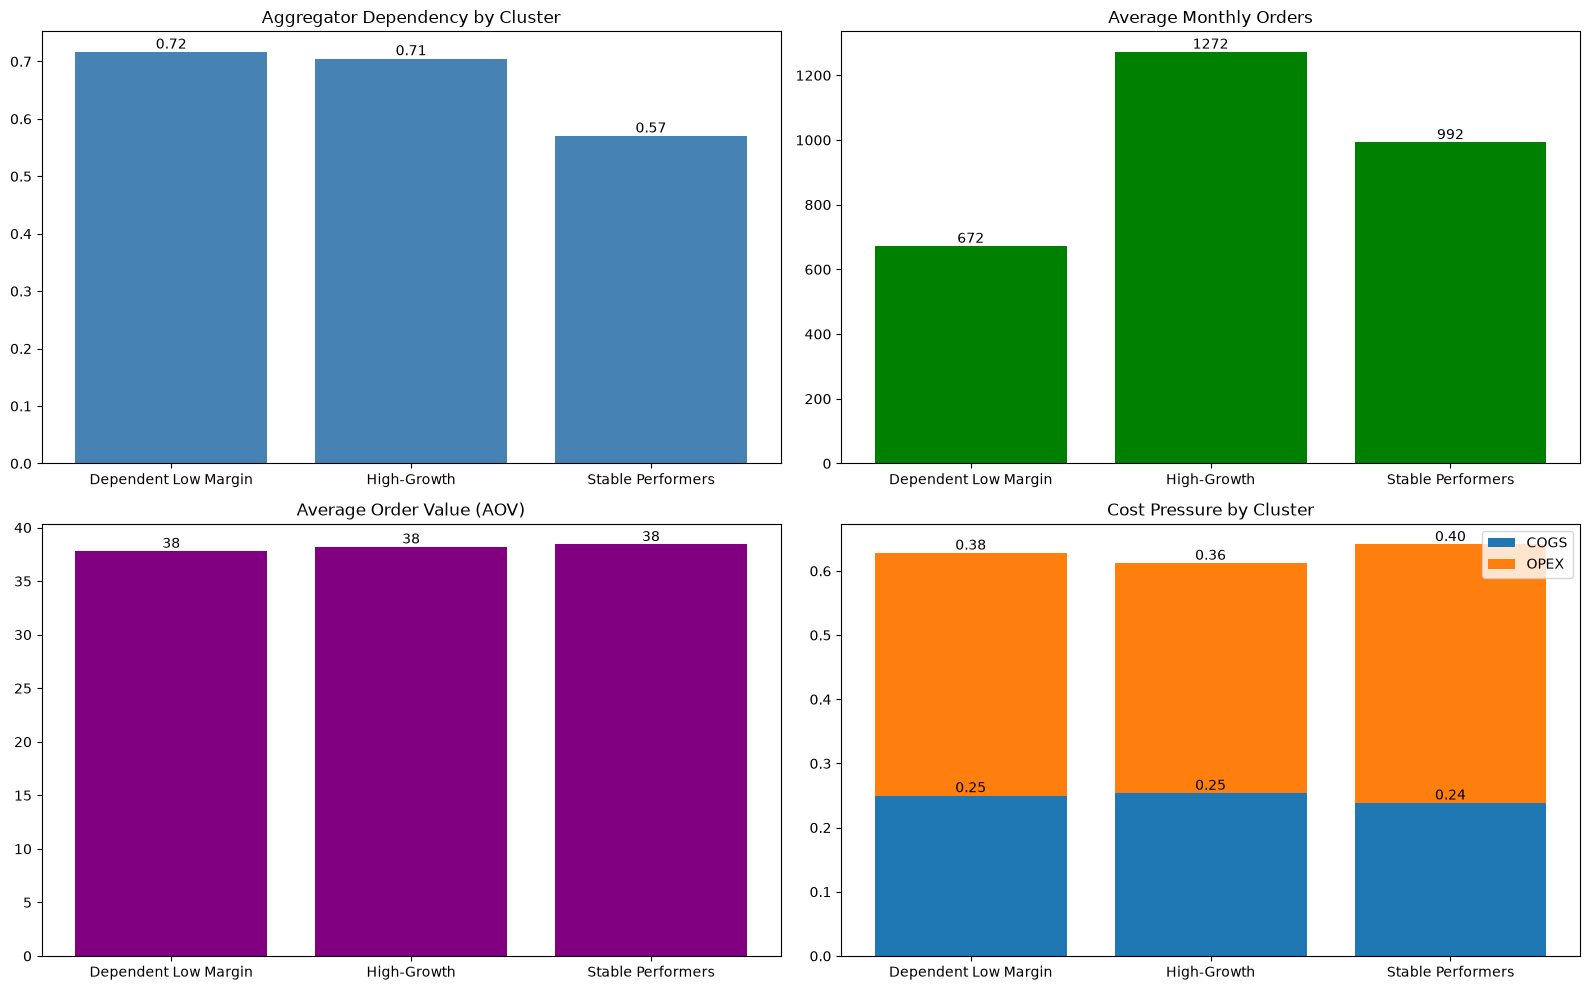

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 10))

# ---------- 1. DELIVERY LEVER ----------
plt.subplot(2, 2, 1)
delivery_ratio = final_df.assign(
    Aggregator_Ratio = (
        final_df["UberEatsOrders"] + final_df["DoorDashOrders"]
    ) / final_df["MonthlyOrders"]
).groupby("Cluster_Label")["Aggregator_Ratio"].mean()

bars1 = plt.bar(delivery_ratio.index, delivery_ratio.values, color="steelblue")
plt.title("Aggregator Dependency by Cluster")
plt.bar_label(bars1, fmt="%.2f")


# ---------- 2. DEMAND LEVER ----------
plt.subplot(2, 2, 2)
orders = final_df.groupby("Cluster_Label")["MonthlyOrders"].mean()

bars2 = plt.bar(orders.index, orders.values, color="green")
plt.title("Average Monthly Orders")
plt.bar_label(bars2, fmt="%.0f")


# ---------- 3. VALUE LEVER ----------
plt.subplot(2, 2, 3)
aov = final_df.groupby("Cluster_Label")["AOV"].mean()

bars3 = plt.bar(aov.index, aov.values, color="purple")
plt.title("Average Order Value (AOV)")
plt.bar_label(bars3, fmt="%.0f")


# ---------- 4. COST LEVER ----------
plt.subplot(2, 2, 4)
costs = final_df.groupby("Cluster_Label")[["COGSRate", "OPEXRate"]].mean()

bars4a = plt.bar(costs.index, costs["COGSRate"], label="COGS")
bars4b = plt.bar(costs.index, costs["OPEXRate"],
                 bottom=costs["COGSRate"], label="OPEX")

plt.title("Cost Pressure by Cluster")
plt.legend()
plt.bar_label(bars4a, fmt="%.2f")
plt.bar_label(bars4b, fmt="%.2f")

plt.tight_layout()
plt.show()
